# FloodNet Dataset Functions

How `scripts/floodnet.py` turns FloodNet into tiles our Houston model can be tested on, and how to use each function.

**FloodNet** is a set of 2,343 drone photos from Hurricane Harvey (Fort Bend County, TX, Aug-Sep 2017), each with a
hand-labeled mask of 10 classes. We use it as an **extra test set only**: the model is still trained on the Houston
scenes, and FloodNet tells us how well it handles photos it has never seen from the same storm.

The photos are very different from our data, so they go through four steps before the model can use them:

| Step | Why | Function |
|---|---|---|
| 1. Remap classes | FloodNet has 10 classes; we have flood / dry / unknown | `load_floodnet_image` |
| 2. Measure pixel size | Each photo was taken from a different height | `meters_per_pixel` |
| 3. Shrink | FloodNet pixels are ~2 cm; ours are 1.8 m | `shrink` |
| 4. Pad to a tile | The model only takes 256 x 256 inputs | `pad_to_tile` |

`get_floodnet_tiles` runs all four steps for every photo (and caches the result), so in practice it is the only
function you need for testing. The sections below walk through each step on one photo. Two more functions build on it:

| Section | Function | Use |
|---|---|---|
| 6 | `get_floodnet_tiles` | **Test** our Houston model: one photo per tile |
| 7 | `get_floodnet_mosaics` | **Train** our Houston model with extra data: many photos packed into each tile, with random flips and rotations |
| 8 | `iter_full_res_tiles` | **Train a separate model** on the original-size photos, with any input size |

Steps 1-4 aren't data *augmentation* in the training sense; they're conversion, making FloodNet look like our data so
the scores mean something. The mosaics in section 7 add real augmentation (random flips, rotations and arrangements).

Run the cells top to bottom.

## 0. Setup

FloodNet must be downloaded to `../data/floodnet/FloodNet-Supervised_v1.0/` (about 13 GB, from the link in the
[BinaLab README](https://github.com/BinaLab/FloodNet-Supervised_v1.0)). `data/` is in `.gitignore`, so it stays out of git.

In [1]:
# pip install numpy pillow matplotlib pandas

%load_ext autoreload
%autoreload 2

import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image

sys.path.append("../scripts")
import floodnet as fn

# Colors used in every label plot below
LABEL_CMAP = ListedColormap(["#d62728", "#ffffff", "#2b6fd6"])  # -1 unknown red, 0 dry white, 1 flood blue
plt.rcParams["figure.facecolor"] = "#e6e6e6"  # light gray behind plots, so white (dry) areas don't blend into the page

## 1. What's in the download

FloodNet comes split into train / val / test. Since we only test on FloodNet, all three splits are test data for us;
the split names are kept so you can pick a subset. Each photo `N.jpg` has a mask `N_lab.png`.

In [2]:
for split in fn.SPLITS:
    print(f"{split:5}  {len(fn.list_names(split))} photos")

print("\nFirst few train names:", fn.list_names("train")[:5])

train  1445 photos
val    450 photos
test   448 photos

First few train names: ['10165', '10166', '10168', '10170', '10171']


## 2. Step 1: Remap 10 classes to flood / dry / unknown

FloodNet's masks store a class id 0-9 per pixel. `REMAP` is a lookup table: `REMAP[class_id]` gives our label.

Decisions behind the table:
- **Pool and Water count as flood (1).** Any standing water is treated as flood, including rivers and ponds that
  were there before the storm.
- **Background is unknown (-1).** It's a mix: mostly lawns and fields, but also a few rivers FloodNet didn't label
  as Water (e.g. photos 7734 and 7736). Ignoring it means those pixels are never scored either way.

In [3]:
pd.DataFrame({"FloodNet class": fn.CLASSES, "our label": fn.REMAP}).rename_axis("class id")

,FloodNet class,our label
class id,,
0,Background,-1
1,Building-flooded,1
2,Building-non-flooded,0
3,Road-flooded,1
4,Road-non-flooded,0
5,Water,1
6,Tree,0
7,Vehicle,0
8,Pool,1


`load_floodnet_image(split, name)` reads one photo and its mask and applies `REMAP`. It returns:
- `rgb`: (H, W, 3) uint8
- `label`: (H, W) int8 with 1 = flood, 0 = dry, -1 = unknown (same convention as `dataset.py`)

rgb: (3000, 4000, 3) uint8 | label: (3000, 4000) int8 values: [0 1]


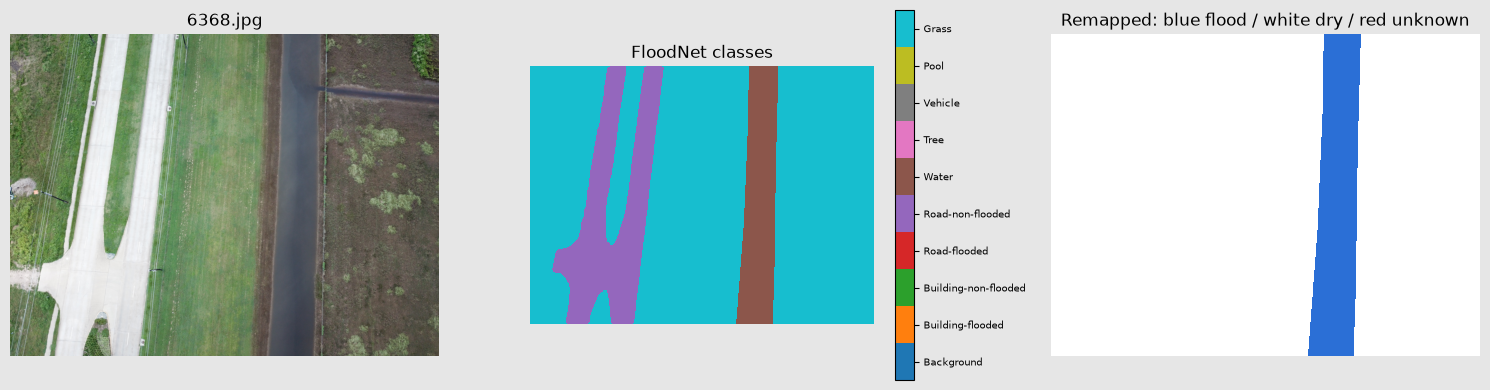

In [4]:
SPLIT, NAME = "train", "6368"

rgb, label = fn.load_floodnet_image(SPLIT, NAME)
classes = np.array(Image.open(fn.FLOODNET_DIR / SPLIT / f"{SPLIT}-label-img" / f"{NAME}_lab.png"))  # raw ids, for comparison

print("rgb:", rgb.shape, rgb.dtype, "| label:", label.shape, label.dtype, "values:", np.unique(label))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(rgb); axes[0].set_title(f"{NAME}.jpg")
im = axes[1].imshow(classes, cmap="tab10", vmin=-0.5, vmax=9.5, interpolation="nearest"); axes[1].set_title("FloodNet classes")
cbar = fig.colorbar(im, ax=axes[1], ticks=range(10)); cbar.ax.set_yticklabels(fn.CLASSES, fontsize=7)
axes[2].imshow(label, cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest"); axes[2].set_title("Remapped: blue flood / white dry / red unknown")
for a in axes: a.axis("off")
plt.tight_layout()
plt.show()

## 3. Step 2: Measure each photo's pixel size

To shrink a photo to 1.8 m per pixel we first need its current size per pixel (the *ground sample distance*):

$$\text{m per px} = \frac{\text{flight height} \times \text{sensor width}}{\text{focal length} \times \text{image width in px}}$$

`meters_per_pixel(split, name)` reads these from the photo itself:
- **Camera model and focal length** from the EXIF tags. Sensor widths for the three cameras in FloodNet are in
  `fn.SENSOR_WIDTH_MM`.
- **Flight height** from DJI's `RelativeAltitude` tag (height above the takeoff point). The 352 Nikon photos don't
  record one, so they use `fn.DEFAULT_ALTITUDE_M` = 60 m, the median of the photos that do.

In [5]:
print("Sensor widths (mm):", fn.SENSOR_WIDTH_MM)
for split, name in [("train", "6368"), ("train", "6998"), ("train", "7736"), ("test", "10823")]:
    print(f"{split}/{name}: {fn.meters_per_pixel(split, name) * 100:.2f} cm per pixel")

Sensor widths (mm): {'FC220': 6.17, 'FC330': 6.17, 'NIKON 1 S2': 13.2}
train/6368: 2.96 cm per pixel
train/6998: 1.72 cm per pixel
train/7736: 1.92 cm per pixel
test/10823: 1.72 cm per pixel


Usually about 2 cm per pixel (1.7-3 cm depending on flight height), roughly **60-100x finer** than our 1.8 m scenes. Training or testing on photos this sharp would
show the model detail it never sees in Houston (a house is ~750 px across here vs. ~8 px in our data), so we shrink them.

## 4. Step 3: Shrink to 1.8 m per pixel

`shrink(rgb, label, m_per_px)` resizes both to `fn.TARGET_M_PER_PX` (1.8 m):
- **RGB** uses a box filter: each new pixel is the average of the block (~90 x 90) of original pixels it covers.
- **Labels** use nearest-neighbor, so every pixel stays exactly -1, 0 or 1 (averaging would create in-between values).

A 4000 x 3000 photo usually comes out about **44 x 33** pixels; photos flown higher, like 6368 (3 cm per pixel), come out larger (66 x 49). Across FloodNet they range from 28 x 21 to 88 x 66. Only large features survive: rivers, ditches and flooded
fields stay visible; cars, pools and single buildings mostly don't.

before: (3000, 4000, 3) -> after: (49, 66, 3) (49, 66)


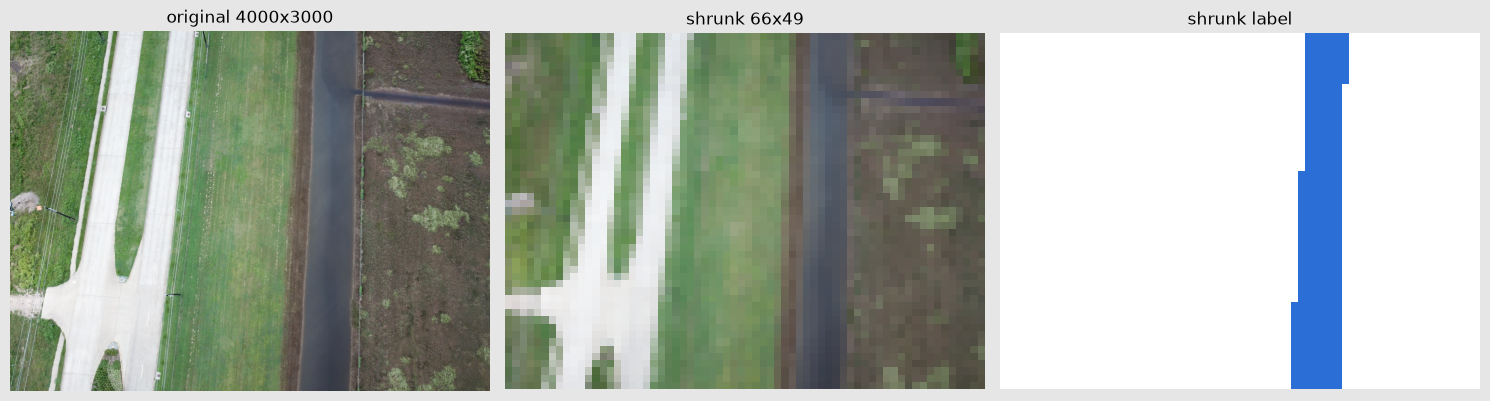

In [6]:
small_rgb, small_label = fn.shrink(rgb, label, fn.meters_per_pixel(SPLIT, NAME))
print("before:", rgb.shape, "-> after:", small_rgb.shape, small_label.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(rgb); axes[0].set_title(f"original {rgb.shape[1]}x{rgb.shape[0]}")
axes[1].imshow(small_rgb, interpolation="nearest"); axes[1].set_title(f"shrunk {small_rgb.shape[1]}x{small_rgb.shape[0]}")
axes[2].imshow(small_label, cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest"); axes[2].set_title("shrunk label")
for a in axes: a.axis("off")
plt.tight_layout()
plt.show()

## 5. Step 4: Pad to a 256 x 256 tile

The U-Net in `unet_pretrained.ipynb` is built for fixed 256 x 256 inputs, so each small photo is placed in the
top-left corner of a tile and the rest is filled in. `pad_to_tile(small_rgb, small_label)` returns:
- `x`: (256, 256, 3) float32, RGB scaled to 0-1 like `dataset.make_input`. The padding **mirrors the photo**, so the
  model doesn't see a hard black edge that could throw off its predictions near the border.
- `y`: (256, 256) int8. The padding is **-1**, so the mirrored filler never counts in the loss or the scores.

Only the real pixels in the corner are ever scored (typically ~1,450, i.e. 2% of the tile); the rest is filler.

x: (256, 256, 3) float32 range 0.16-0.97
y: (256, 256) int8 values: [-1  0  1]
labeled (scored) pixels: 3234 of 65536


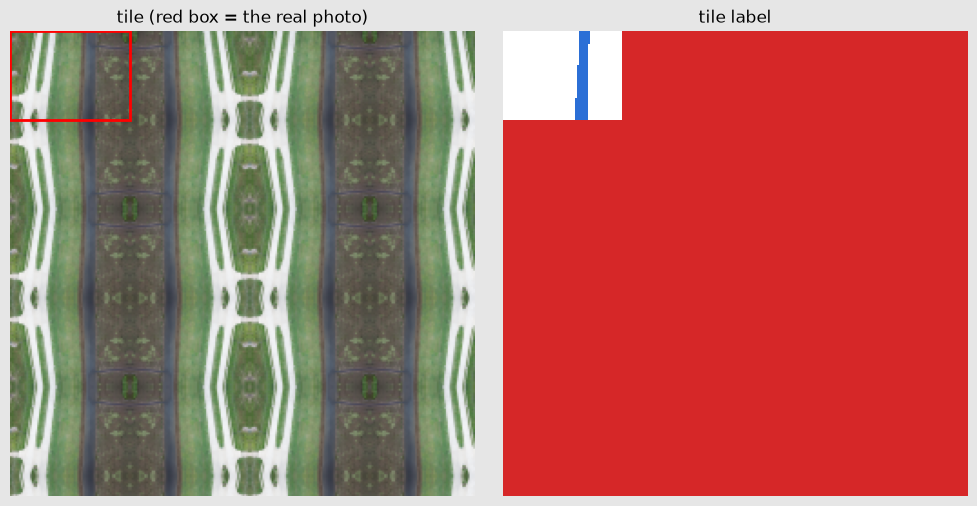

In [7]:
x_tile, y_tile = fn.pad_to_tile(small_rgb, small_label)
print("x:", x_tile.shape, x_tile.dtype, f"range {x_tile.min():.2f}-{x_tile.max():.2f}")
print("y:", y_tile.shape, y_tile.dtype, "values:", np.unique(y_tile))
print("labeled (scored) pixels:", (y_tile != -1).sum(), "of", y_tile.size)

h, w = small_label.shape
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(x_tile)
axes[0].add_patch(plt.Rectangle((-0.5, -0.5), w, h, fill=False, edgecolor="red", lw=2))
axes[0].set_title("tile (red box = the real photo)")
axes[1].imshow(y_tile, cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest"); axes[1].set_title("tile label")
for a in axes: a.axis("off")
plt.tight_layout()
plt.show()

## 6. All photos at once: `get_floodnet_tiles`

`get_floodnet_tiles(splits=fn.SPLITS)` runs steps 1-4 for every photo and returns:
- `X`: (N, 256, 256, 3) float32, the same layout as the RGB part of `dataset.get_tiles`, so
  `X[..., :3]` and the notebook's `preprocess` work unchanged.
- `y`: (N, 256, 256) int8, the same labels as `dataset.get_tiles`.

**Caching.** Reading 2,343 full-size photos takes about 9 minutes, so the first call runs `fn.build_cache()` and
saves the shrunken photos (not the padding) to `../data/floodnet/small_1.8m.npz`, about 12 MB. After that, every call
just loads that file and pads, which takes a few seconds. If you ever change `REMAP`, `TARGET_M_PER_PX` or the shrinking
code, delete the cache file (or call `fn.build_cache()`) so it gets rebuilt.

In [8]:
print("cache exists:", fn.CACHE.exists())

t = time.time()
X, y = fn.get_floodnet_tiles()
print(f"loaded in {time.time() - t:.1f}s")
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)

known = y[y != -1]
print(f"labeled pixels: {known.size:,}  flood: {known.mean():.1%}  dry: {1 - known.mean():.1%}")

cache exists: True


loaded in 2.9s
X: (2343, 256, 256, 3) float32 | y: (2343, 256, 256) int8
labeled pixels: 4,353,627  flood: 15.8%  dry: 84.2%


Pass `splits` to get only some of FloodNet's splits, e.g. just its test split:

In [9]:
X_fn_test, y_fn_test = fn.get_floodnet_tiles(["test"])
print(X_fn_test.shape, y_fn_test.shape)

(448, 256, 256, 3) (448, 256, 256)


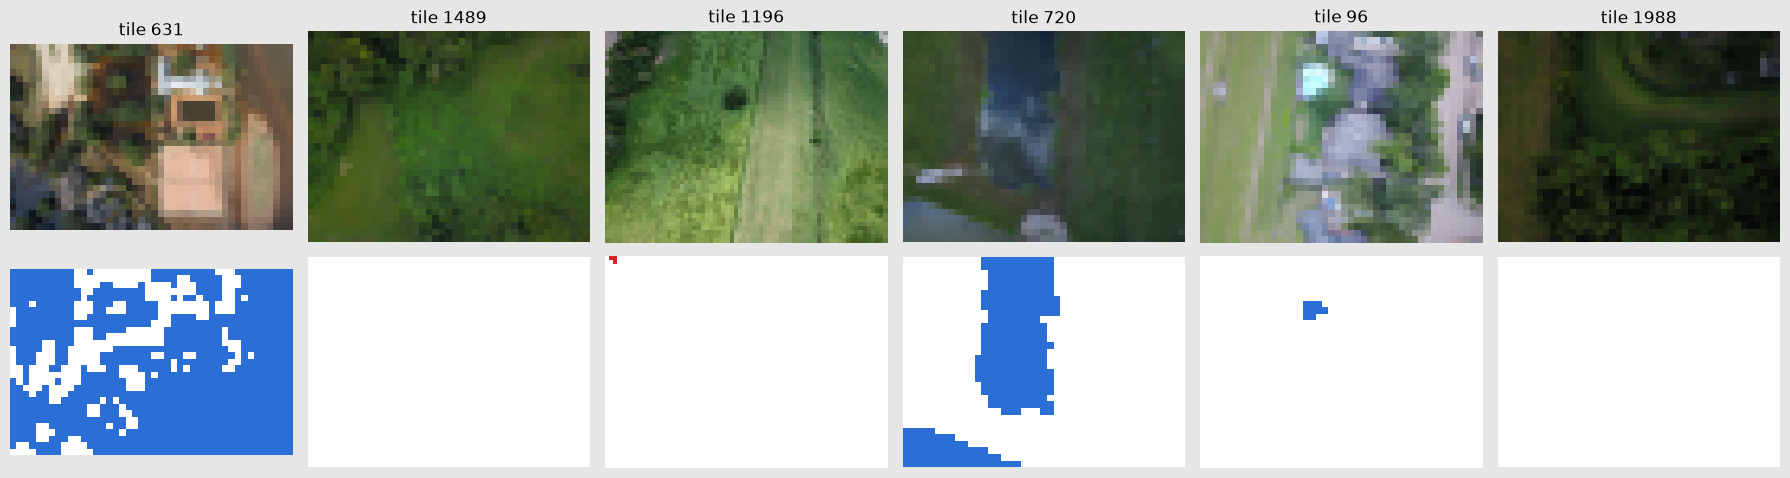

In [10]:
# A few random tiles, cropped to their labeled area (the real photo, minus any unknown edges) so it's easy to see
rng = np.random.default_rng(0)
picks = rng.choice(len(X), 6, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(18, 5))
for col, i in enumerate(picks):
    rows, cols = np.nonzero(y[i] != -1)
    h, w = rows.max() + 1, cols.max() + 1
    axes[0, col].imshow(X[i, :h, :w], interpolation="nearest"); axes[0, col].set_title(f"tile {i}")
    axes[1, col].imshow(y[i, :h, :w], cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest")
for a in axes.ravel(): a.axis("off")
plt.tight_layout()
plt.show()

## 7. Mosaics for training at the Houston scale: `get_floodnet_mosaics`

`get_floodnet_tiles` is fine for **testing**, but it's a poor way to **train**: each tile is ~97% filler, so the model
would spend almost all its time on padding. `get_floodnet_mosaics` packs many shrunken photos into each 256 x 256
tile instead, so most of every tile is real photo. Use it to add FloodNet to the Houston training data.

```python
fn.get_floodnet_mosaics(splits=("train",), seed=None, flip_rotate=True)
```

| Argument | Meaning |
|---|---|
| `splits` | which FloodNet splits to use. Defaults to `["train"]`, so FloodNet's test split stays free for testing |
| `seed` | controls the random order, flips and rotations. Same seed = same tiles; a new seed = a new arrangement |
| `flip_rotate` | randomly rotate (0/90/180/270 degrees) and flip each photo before packing |

It returns the same format as `get_floodnet_tiles`: `X` (N, 256, 256, 3) float32 RGB 0-1, `y` (N, 256, 256) int8.

### How a mosaic tile is built

1. **Shuffle.** Take the shrunken photos from the cache (the ~44 x 33 photos from step 3) in a random order.
2. **Flip and rotate** each photo at random (`random_flip_rotate`). The same change is applied to its label, so
   the labels still line up. A flooded road looks the same from any direction, so this gives the model more
   variety for free.
3. **Fill rows left to right, like words on a page.** Photos are added to a row until it reaches the right edge
   of the tile, then a new row starts below it.
4. **Even out each row.** A row is as tall as its tallest photo. Shorter photos are mirror-padded down to fill the
   gap (labels -1), so there are no blank holes, the same trick as step 4.
5. **Cut off at the edges.** The last photo in a row usually hangs over the right edge, and the last row over the
   bottom edge; those parts are cut off. Because every seed gives a new arrangement, different parts get cut each time.
6. **Start a new tile** when the current one is full, until every photo is used. The final tile only holds the
   leftovers, so its empty bottom is mirrored image with -1 labels.

```
 one tile (256 x 256)
┌──────┬─────┬──────┬──────┬───┐   row 1: as tall as its tallest photo
│  A   │  B  │  C   │  D   │ E │ <- E hangs past the edge and is cut off
│      ├─────┤      ├──────┤   │
│      │ ~~~ │      │ ~~~  │   │ <- ~~~ = mirrored filler under shorter photos (label -1)
├────┬─┴─────┴┬─────┴┬─────┴┬──┤   row 2
│ F  │   G    │  H   │  I   │J │
│    │        │      │      │  │
├────┴──┬─────┴──┬───┴──┬───┴──┤   ...
│  K    │   L    │  M   │  N   │ <- the last row is cut off at the bottom edge
└───────┴────────┴──────┴──────┘
```

In [11]:
t = time.time()
X_mos, y_mos = fn.get_floodnet_mosaics(["train"], seed=0)
print(f"built in {time.time() - t:.1f}s")
print("X:", X_mos.shape, X_mos.dtype, "| y:", y_mos.shape, y_mos.dtype, "values:", np.unique(y_mos))

# Compare with one photo per tile
X_one, y_one = fn.get_floodnet_tiles(["train"])
_, small_labels = fn.load_small_photos(["train"])
labeled_in_photos = sum((l != -1).sum() for l in small_labels)

pd.DataFrame({
    "tiles": [len(X_one), len(X_mos)],
    "real (labeled) share of a tile": [f"{(y_one != -1).mean():.0%}", f"{(y_mos[:-1] != -1).mean():.0%}"],
    "labeled pixels used": [f"{(y_one != -1).sum() / labeled_in_photos:.0%}", f"{(y_mos != -1).sum() / labeled_in_photos:.0%}"],
    "flood share": [f"{y_one[y_one != -1].mean():.1%}", f"{y_mos[y_mos != -1].mean():.1%}"],
}, index=["one photo per tile", "mosaic"])

built in 0.3s
X: (47, 256, 256, 3) float32 | y: (47, 256, 256) int8 values: [-1  0  1]


,tiles,real (labeled) share of a tile,labeled pixels used,flood share
one photo per tile,1445,3%,100%,15.9%
mosaic,47,74%,84%,15.8%


The mosaic needs ~30x fewer tiles for the same photos, and ~74% of each tile is real labeled photo instead of ~3%
(the rest is mirrored filler under shorter photos, plus FloodNet's Background class). About 16% of the labeled
pixels are cut off at the tile edges in any one arrangement. The flood share doesn't change, so packing doesn't bias
the labels.

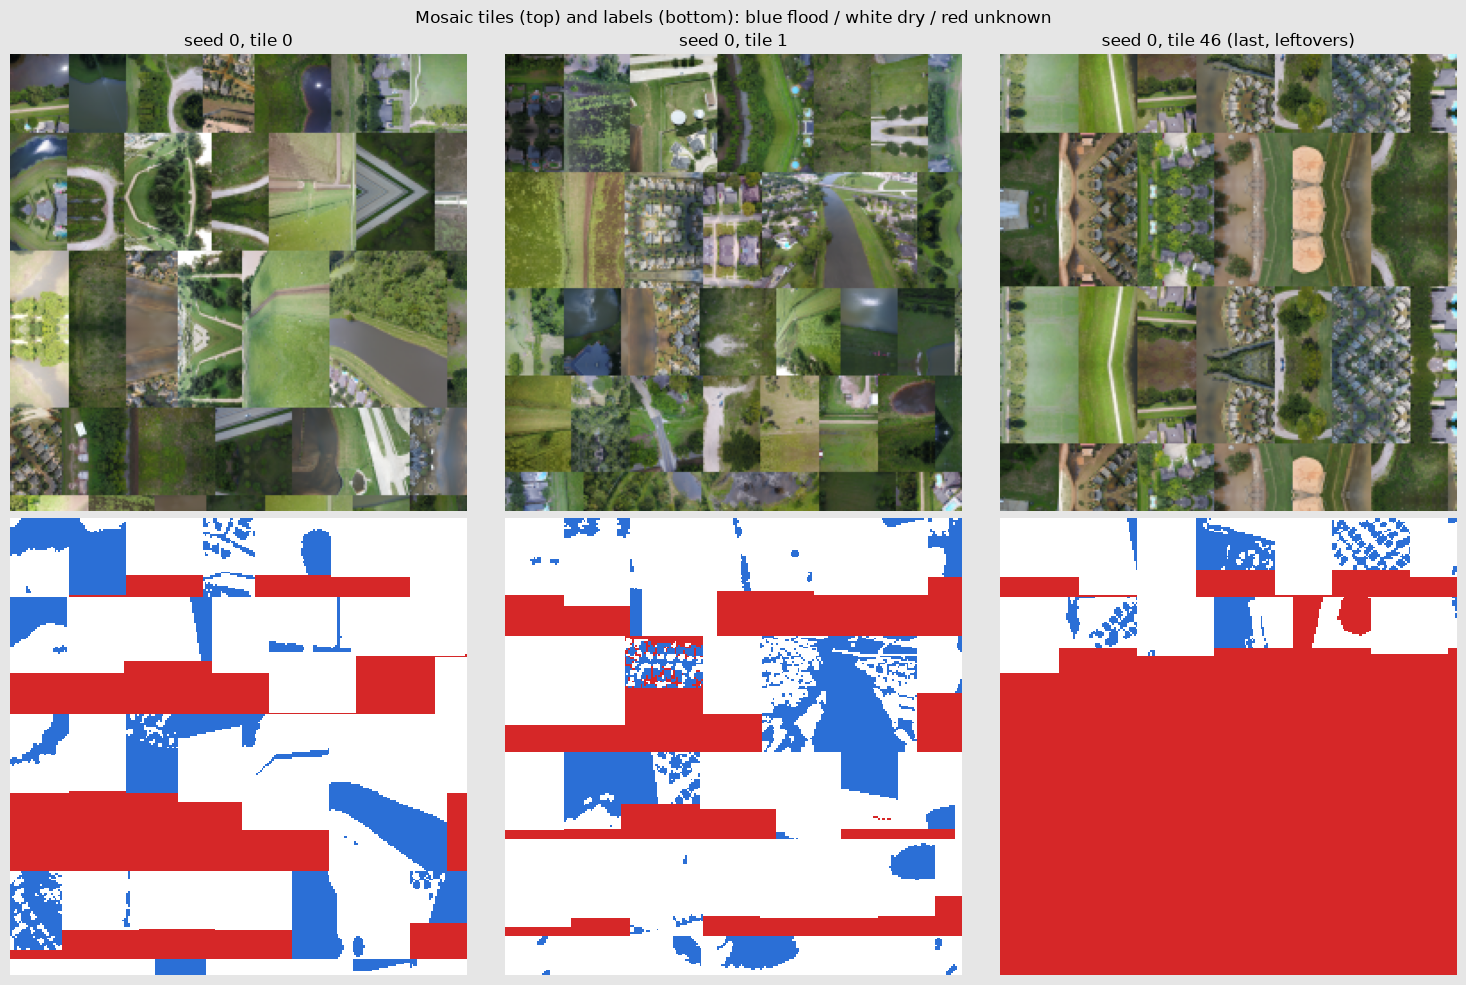

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for col, i in enumerate([0, 1, len(X_mos) - 1]):
    axes[0, col].imshow(X_mos[i]); axes[0, col].set_title(f"seed 0, tile {i}" + (" (last, leftovers)" if i == len(X_mos) - 1 else ""))
    axes[1, col].imshow(y_mos[i], cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Mosaic tiles (top) and labels (bottom): blue flood / white dry / red unknown")
plt.tight_layout()
plt.show()

### Flips and rotations

`random_flip_rotate(rgb, label, rng)` is what step 2 uses. Here it is on one photo, eight times. The label always
turns with the photo.

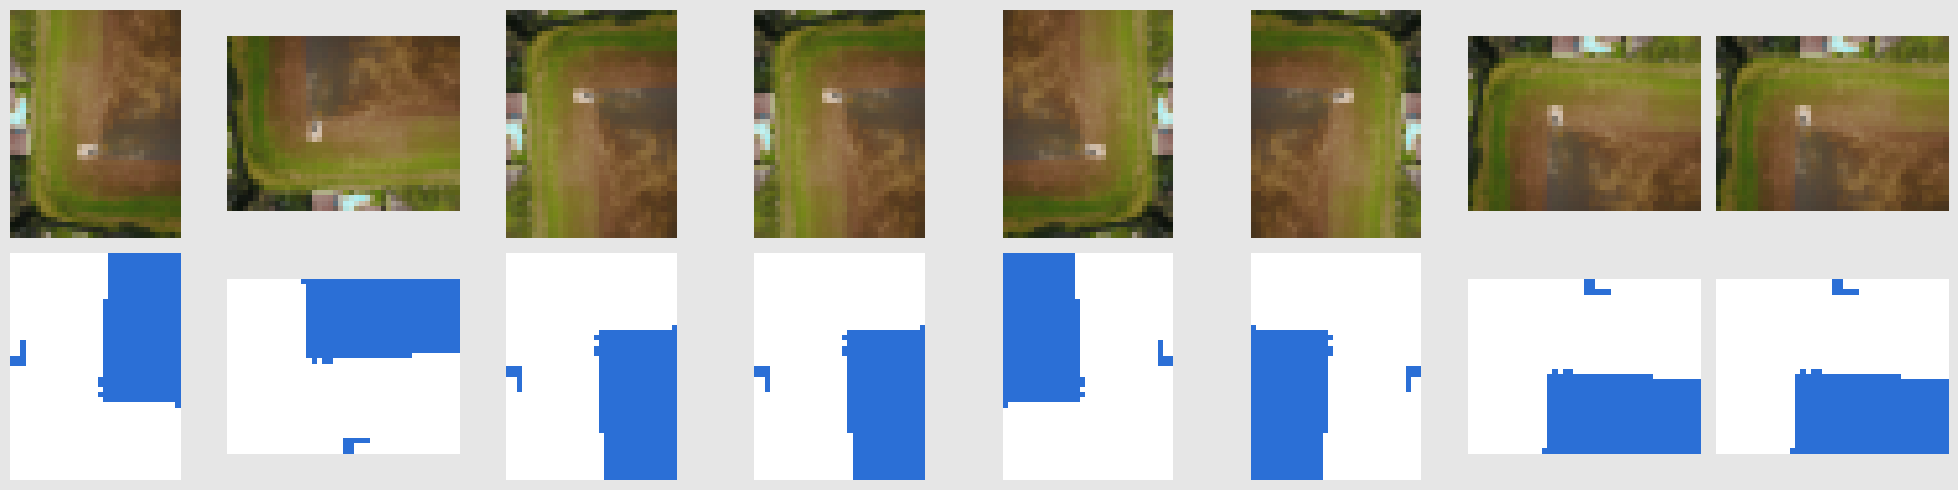

In [13]:
rgbs, labels = fn.load_small_photos(["train"])
# Pick a photo with both flood and dry so it's easy to see the label turn with the photo
pick = next(i for i, l in enumerate(labels) if 0.3 < (l == 1).mean() < 0.7 and (l == 0).mean() > 0.3)
rng = np.random.default_rng(1)

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for col in range(8):
    r, l = fn.random_flip_rotate(rgbs[pick], labels[pick], rng)
    axes[0, col].imshow(r, interpolation="nearest")
    axes[1, col].imshow(l, cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest")
for a in axes.ravel(): a.axis("off")
plt.tight_layout()
plt.show()

### A new arrangement every epoch

The same seed always gives the same tiles, and a different seed gives a completely different packing. Training with
`seed=epoch` shows the model new neighbors, new rotations and different cut-off edges every epoch, so it can't
memorize one layout or learn the seams between photos.

seed 0 twice, identical: True
seed 0 vs seed 1, identical: False


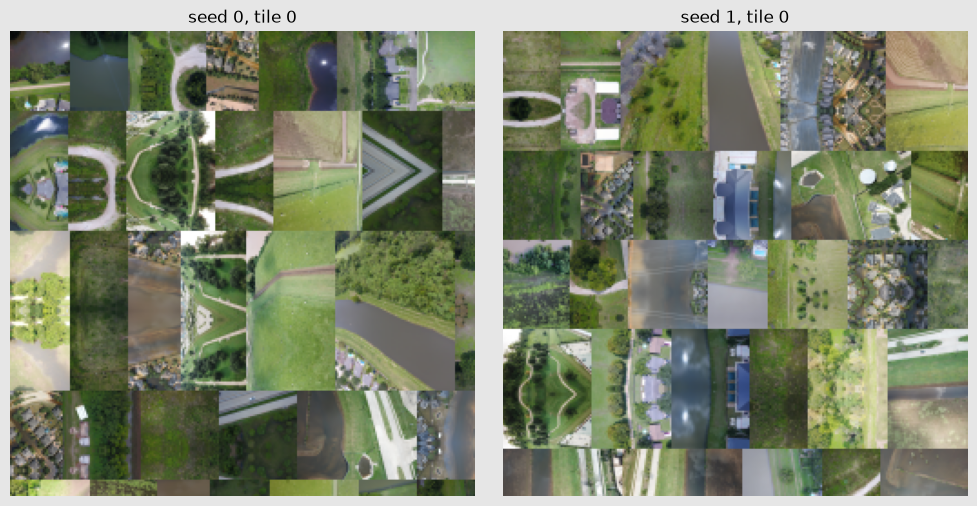

In [14]:
X_a, _ = fn.get_floodnet_mosaics(["train"], seed=0)
X_b, _ = fn.get_floodnet_mosaics(["train"], seed=1)
print("seed 0 twice, identical:", np.array_equal(X_mos, X_a))
print("seed 0 vs seed 1, identical:", np.array_equal(X_mos, X_b))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(X_mos[0]); axes[0].set_title("seed 0, tile 0")
axes[1].imshow(X_b[0]); axes[1].set_title("seed 1, tile 0")
for a in axes: a.axis("off")
plt.tight_layout()
plt.show()

### Using it in training (Keras)

Not run here, since TensorFlow isn't installed in this environment. Variable names are from `unet_pretrained.ipynb`.
Build new mosaics each epoch and train on them together with the Houston tiles:

```python
EPOCHS = 5
for epoch in range(EPOCHS):
    X_fn, y_fn = fn.get_floodnet_mosaics(["train"], seed=epoch)   # new arrangement each epoch

    X_mix = np.concatenate([X_train_rgb, X_fn])                   # Houston RGB tiles + FloodNet mosaics
    y_mix = np.concatenate([y_train, y_fn])

    model.fit(preprocess(X_mix), prepare_labels(y_mix),
              validation_data=(X_val_in, y_val_in),
              batch_size=8, epochs=1, shuffle=True, callbacks=[checkpoint])
```

Then score the model on the Houston test set **and** on FloodNet's test split
(`fn.get_floodnet_tiles(["test"])`), and compare with a model trained on Houston only. That comparison shows whether
FloodNet actually helps.

Things to know:
- **It's a small addition.** All of FloodNet's train split fits in ~47 mosaic tiles at our scale. Extra examples,
  mostly of dry ground, but not a big dataset.
- **Seams.** Rivers and roads stop sharply where one photo meets the next. A new seed every epoch keeps this from
  becoming a pattern the model can learn.
- **Only use `["train"]`** (and `["val"]` if you want), never `["test"]`, so FloodNet's test split stays a fair test.

## 8. Original-size data for a new model: `iter_full_res_tiles`

Everything above shrinks FloodNet to fit **our Houston model**. If you want to train a **new model** on FloodNet
at drone resolution, with a different input size, use `iter_full_res_tiles` instead. It skips the shrinking and
padding and cuts tiles straight from the original 4000 x 3000 photos (classes are still remapped to flood / dry /
unknown).

```python
fn.iter_full_res_tiles(splits=fn.SPLITS, tile=512, stride=None, max_unknown=1.0, downscale=1, shuffle=False, seed=None)
```

| Argument | Meaning |
|---|---|
| `splits` | which FloodNet splits to read, e.g. `["train"]` |
| `tile` | the new model's input size (512 -> 512 x 512 tiles). Any size works |
| `stride` | step between tiles; defaults to `tile` (no overlap). `tile // 2` gives 50% overlap, like our training tiles |
| `max_unknown` | skip tiles where more than this share of pixels is -1 (1.0 keeps everything) |
| `downscale` | shrink the photo by this factor before cutting. 1 = original size (~2 cm/px). 4 = ~8 cm/px, so each tile covers 16x more ground |
| `shuffle`, `seed` | shuffle the order of photos |

It **yields one `(x, y)` tile at a time** instead of returning arrays: all 2,343 photos at full size would need
about 84 GB of memory (4x more as float32), far more than fits. Each tile has the same format as before:
`x` (tile, tile, 3) float32 RGB 0-1, `y` (tile, tile) int8.

The cutting uses the same sliding window as `dataset.cut_tiles`: the last row and column snap to the photo's edge,
so nothing is cut off. If the photo is smaller than the tile (e.g.  on a 1000 x 750 photo),
it's padded first the same way as step 4: mirrored image, -1 labels.

In [15]:
# Cut the first photo of FloodNet's test split into 512 x 512 tiles
first_photo = fn.iter_full_res_tiles(splits=["test"], tile=512)
tiles = []
for x_t, y_t in first_photo:
    tiles.append((x_t, y_t))
    if len(tiles) == 48:   # a 4000 x 3000 photo gives 8 x 6 = 48 tiles at 512
        break

x_t, y_t = tiles[0]
print("x:", x_t.shape, x_t.dtype, "| y:", y_t.shape, y_t.dtype, "values:", np.unique(y_t))
print("tiles from one photo:", len(tiles))
print(f"one photo at full size: {3000 * 4000 * 3 / 1e6:.0f} MB as uint8 -> all 2,343: {2343 * 3000 * 4000 * 3 / 1e9:.0f} GB")

x: (512, 512, 3) float32 | y: (512, 512) int8 values: [0]
tiles from one photo: 48
one photo at full size: 36 MB as uint8 -> all 2,343: 84 GB


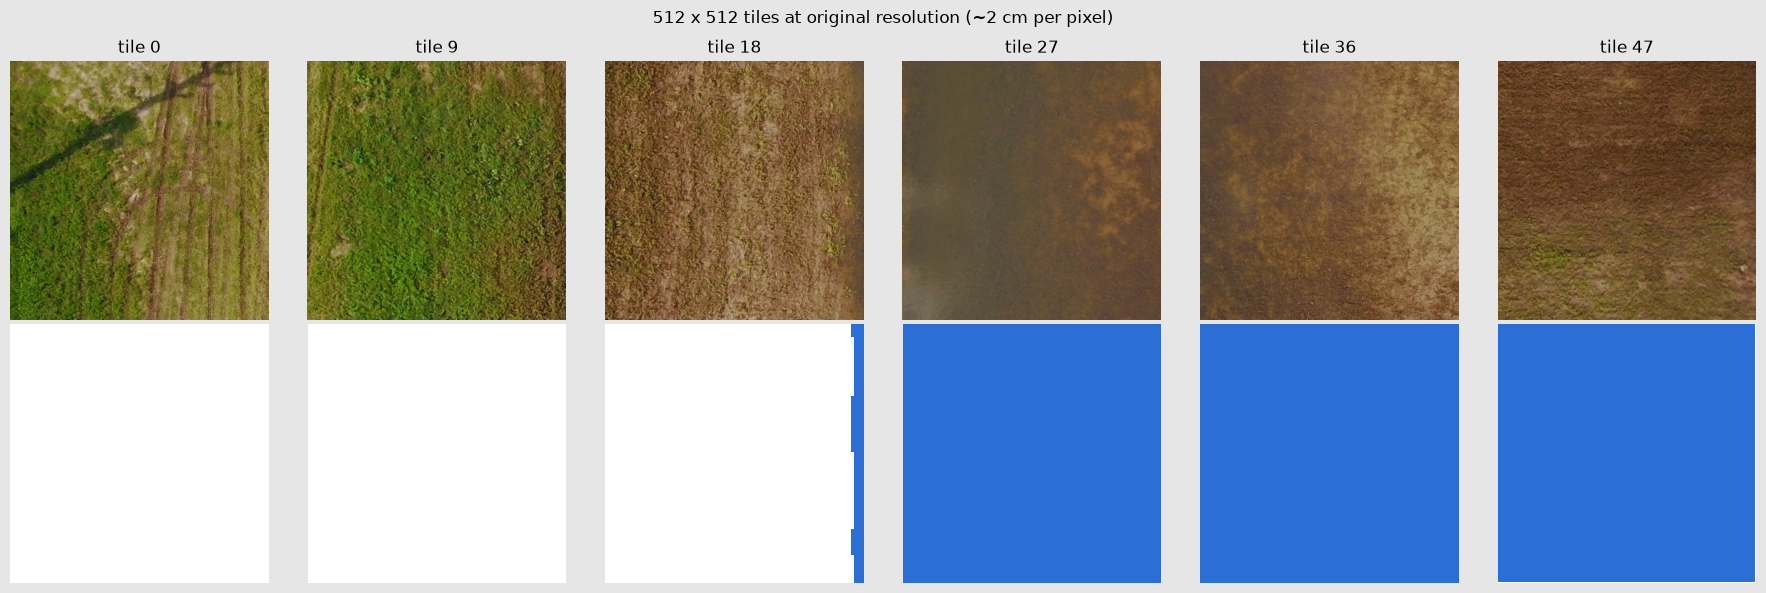

In [16]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for col, i in enumerate([0, 9, 18, 27, 36, 47]):
    axes[0, col].imshow(tiles[i][0]); axes[0, col].set_title(f"tile {i}")
    axes[1, col].imshow(tiles[i][1], cmap=LABEL_CMAP, vmin=-1, vmax=1, interpolation="nearest")
for a in axes.ravel(): a.axis("off")
plt.suptitle("512 x 512 tiles at original resolution (~2 cm per pixel)")
plt.tight_layout()
plt.show()

Tile count and how much ground one tile covers, for a few settings (4000 x 3000 photo, no overlap):

In [17]:
rows = []
for tile, downscale in [(256, 1), (512, 1), (512, 4), (1024, 4)]:
    H, W = 3000 // downscale, 4000 // downscale
    n = len(range(0, H - tile, tile)) + 1
    m = len(range(0, W - tile, tile)) + 1
    rows.append({"tile": tile, "downscale": downscale, "tiles per photo": n * m,
                 "tiles in all of FloodNet (approx)": n * m * 2343,
                 "one tile covers (m)": round(tile * downscale * 0.02, 1)})
pd.DataFrame(rows)

,tile,downscale,tiles per photo,tiles in all of FloodNet (approx),one tile covers (m)
0,256,1,192,449856,5.1
1,512,1,48,112464,10.2
2,512,4,4,9372,41.0
3,1024,4,1,2343,81.9


### Training a new model with it (Keras)

Not run here, since TensorFlow isn't installed in this environment. `tf.data.Dataset.from_generator` turns the
generator into a dataset that Keras can train on without loading everything into memory. The model's `Input`
shape has to match `tile`. The rest (the masked loss, the ResNet50 `preprocess`) works the same as in
`unet_pretrained.ipynb`.

```python
import tensorflow as tf

TILE = 512

def floodnet_dataset(splits, shuffle):
    gen = lambda: fn.iter_full_res_tiles(splits, tile=TILE, max_unknown=0.5, shuffle=shuffle)
    ds = tf.data.Dataset.from_generator(gen, output_signature=(
        tf.TensorSpec((TILE, TILE, 3), tf.float32),
        tf.TensorSpec((TILE, TILE), tf.int8),
    ))
    ds = ds.map(lambda x, y: (preprocess(x), tf.cast(y, tf.float32)[..., None]))
    if shuffle:
        ds = ds.shuffle(500)   # mixes tiles from different photos
    return ds.batch(8).prefetch(tf.data.AUTOTUNE)

train_ds = floodnet_dataset(["train"], shuffle=True)
val_ds = floodnet_dataset(["val"], shuffle=False)

model, encoder = build_resnet50_unet((TILE, TILE, 3))   # same builder, new input size
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_bce)
model.fit(train_ds, validation_data=val_ds, epochs=5)
```

Keep FloodNet's splits separate: train on `["train"]`, validate on `["val"]`, and keep `["test"]` for the final score.
Reading every photo takes several minutes per epoch; if that's too slow, use a larger `downscale` or save the tiles
to disk once.

**Three different uses, don't mix them up:**
- `get_floodnet_tiles`: FloodNet shrunk to 1.8 m, one photo per tile, to **test our Houston model**.
- `get_floodnet_mosaics`: FloodNet shrunk to 1.8 m, packed into mosaics, to **add training data to our Houston model**.
- `iter_full_res_tiles`: FloodNet at (near) original size, to **train a separate FloodNet model**. A model trained
  this way expects ~2 cm pixels, so it won't work directly on our 1.8 m Houston scenes.

## 9. Things to keep in mind

- **FloodNet is mostly dry** (~16% flood of labeled pixels), while our Houston data is mostly flooded. Report IoU or
  F1 for the flood class, not plain accuracy: a model that always says "dry" would get ~84% accuracy here.
- **No DEM.** FloodNet has no elevation, so these tiles only fit the RGB-only model, not a model trained on RGB + DEM.
- **Labels are coarse in places.** Some photos are labeled all-flood even where part of the ground looks dry
  (e.g. train/10165), and some rivers are labeled Background, which we ignore.
- **Never train on the tiles you test on.** Train with FloodNet's `["train"]` split (mosaics or full-size tiles) and keep
  its `["test"]` split out of training, so its score still measures generalization.